### Célula 0

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from databricks import sql

load_dotenv()

# Parâmetro do pipeline — "store" ou "warehouse".
# Trocar aqui e reexecutar o notebook do início é o que gera a segunda passagem (Centro de Distribuição),
# sem duplicar nenhuma lógica de query.
LOCATION_TYPE = "warehouse"   # trocar para "warehouse" na segunda execução

connection = sql.connect(
    server_hostname=os.environ["DATABRICKS_HOST"],
    http_path=os.environ["DATABRICKS_HTTP_PATH"],
    access_token=os.environ["DATABRICKS_TOKEN"],
    catalog=os.environ.get("DATABRICKS_CATALOG", "dev"),
    schema="gold",
)

def run_query(query: str) -> pd.DataFrame:
    """Executa uma query no SQL Warehouse e retorna um DataFrame pandas."""
    with connection.cursor() as cursor:
        cursor.execute(query)
        if cursor.description is None:
            return pd.DataFrame()
        rows = cursor.fetchall()
        columns = [desc[0] for desc in cursor.description]
        return pd.DataFrame(rows, columns=columns)

### Célula 1

In [12]:
run_query(f"""
CREATE OR REPLACE TEMP VIEW eda_base AS
SELECT
    f.product_variant_id,
    p.product_name,
    p.category_name,
    f.location_id,
    l.name        AS location_name,
    c.ano,
    c.mes,
    DATE(CONCAT(c.ano, '-', LPAD(c.mes, 2, '0'), '-01')) AS mes_ref,
    SUM(f.quantity)           AS quantidade_mes,
    SUM(f.valor_liquido_item) AS valor_liquido_mes
FROM fct_orders f
JOIN dim_produtos  p ON f.product_variant_id = p.product_variant_id
JOIN dim_locations l ON f.location_id        = l.location_id
JOIN dim_calendar  c ON f.placed_at_key      = c.date_key
WHERE l.location_type = '{LOCATION_TYPE}'
GROUP BY f.product_variant_id, p.product_name, p.category_name, f.location_id, l.name, c.ano, c.mes
""")

,Result


### Célula 2

count    3027.000000
mean      136.464486
std        30.885569
min        33.000000
10%        98.000000
25%       114.000000
50%       136.000000
75%       157.500000
90%       178.000000
95%       189.000000
99%       211.000000
max       261.000000
Name: quantidade_total, dtype: float64


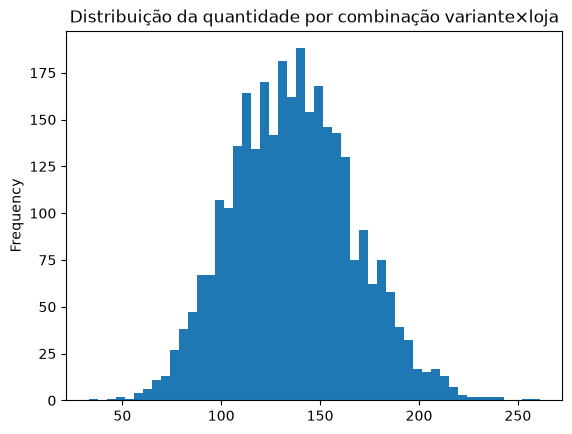

count          3027
unique         3027
top       426149.51
freq              1
Name: valor_total, dtype: object


In [13]:
df_vol = run_query("""
    SELECT product_variant_id, location_id,
           SUM(quantidade_mes)    AS quantidade_total,
           SUM(valor_liquido_mes) AS valor_total
    FROM eda_base
    GROUP BY product_variant_id, location_id
""")

# Métrica principal: quantidade (o que orienta disponibilidade de estoque)
print(df_vol['quantidade_total'].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))
df_vol.sort_values('quantidade_total', ascending=False).head(20)   # top 20 combinações por demanda
df_vol.sort_values('quantidade_total', ascending=True).head(20)    # bottom 20 (candidatas a esparsidade)

df_vol['quantidade_total'].plot(kind='hist', bins=50, title='Distribuição da quantidade por combinação variante×loja')
plt.show()

# Métrica secundária: valor líquido, só como contexto (não usado para ranking nesta EDA)
print(df_vol['valor_total'].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))

### Célula 3

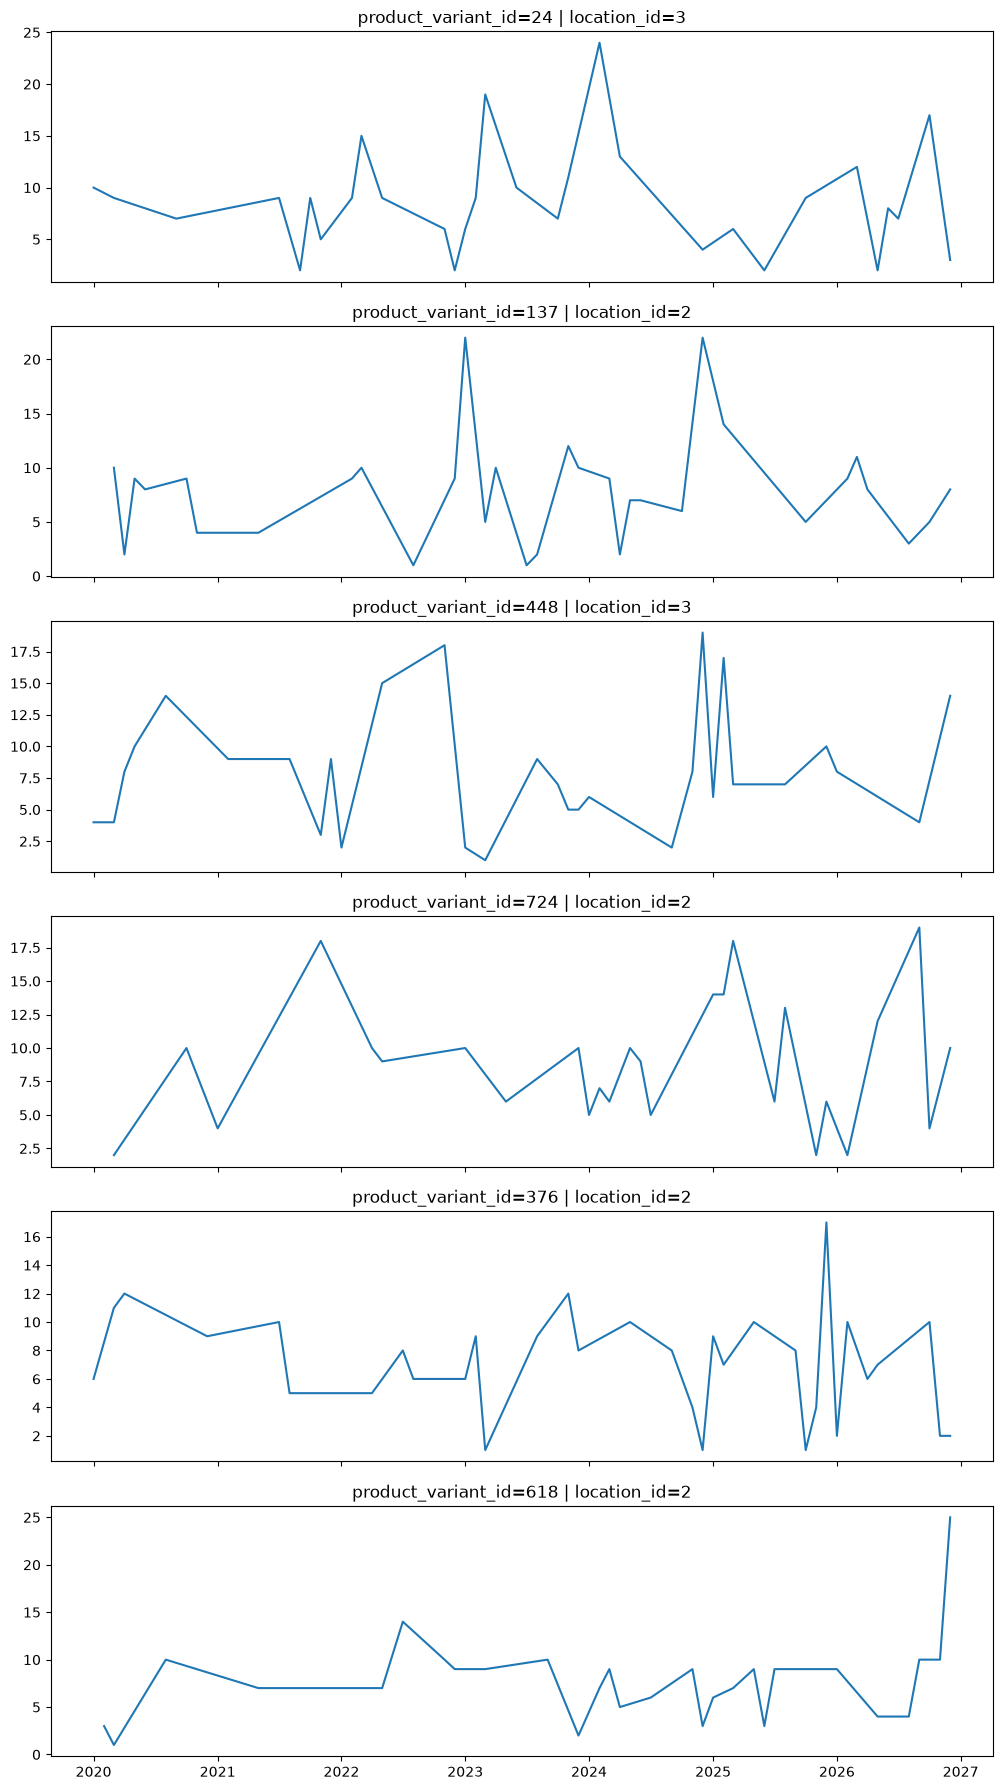

In [14]:
top_combos = df_vol.sort_values('quantidade_total', ascending=False).head(6)[['product_variant_id','location_id']]

df_serie = run_query("""
    SELECT product_variant_id, location_id, mes_ref, quantidade_mes, valor_liquido_mes
    FROM eda_base
""")

fig, axes = plt.subplots(len(top_combos), 1, figsize=(10, 3*len(top_combos)), sharex=True)
for ax, (_, row) in zip(axes, top_combos.iterrows()):
    sub = df_serie[(df_serie.product_variant_id==row.product_variant_id) & (df_serie.location_id==row.location_id)].sort_values('mes_ref')
    ax.plot(sub.mes_ref, sub.quantidade_mes)   # série principal: quantidade
    ax.set_title(f"product_variant_id={row.product_variant_id} | location_id={row.location_id}")
plt.tight_layout()
plt.show()

### Célula 4

In [ ]:
run_query("""
CREATE OR REPLACE TEMP VIEW eda_historico AS
WITH janela_combinacao AS (
    SELECT
        product_variant_id,
        location_id,
        MIN(mes_ref)              AS min_mes_combinacao,
        MAX(mes_ref)              AS max_mes_combinacao,
        COUNT(DISTINCT mes_ref)   AS meses_com_venda
    FROM eda_base
    GROUP BY product_variant_id, location_id
)
SELECT
    product_variant_id,
    location_id,
    meses_com_venda,
    MONTHS_BETWEEN(max_mes_combinacao, min_mes_combinacao) + 1 AS meses_de_vida,
    (MONTHS_BETWEEN(max_mes_combinacao, min_mes_combinacao) + 1) - meses_com_venda AS meses_com_demanda_zero,
    ROUND(meses_com_venda / (MONTHS_BETWEEN(max_mes_combinacao, min_mes_combinacao) + 1), 3) AS pct_cobertura
FROM janela_combinacao
""")

df_hist = run_query("SELECT * FROM eda_historico")

# Distribuição por faixa de cobertura — insumo direto do limiar "série madura vs. esparsa"
bins = [0, .25, .5, .75, .9, 1.0]
df_hist['faixa_cobertura'] = pd.cut(df_hist['pct_cobertura'], bins=bins, include_lowest=True)
tabela_cobertura = df_hist['faixa_cobertura'].value_counts(normalize=True).sort_index()
print(tabela_cobertura)

# Checagem rápida: a distribuição de meses_de_vida varia entre combinações?
# Se toda combinação tiver o mesmo meses_de_vida (≈ janela do dataset inteiro), é sinal de que
# a maioria dos produtos já existia desde o início do histórico — informação útil por si só.
print(df_hist['meses_de_vida'].describe(percentiles=[.1, .5, .9]))

faixa_cobertura
(-0.001, 0.25]    0.395771
(0.25, 0.5]       0.604229
(0.5, 0.75]       0.000000
(0.75, 0.9]       0.000000
(0.9, 1.0]        0.000000
Name: proportion, dtype: float64
count    3027.000000
mean       78.390486
std         5.662648
min        43.000000
10%        71.000000
50%        81.000000
90%        84.000000
max        84.000000
Name: meses_de_vida, dtype: float64


### Célula 5.1

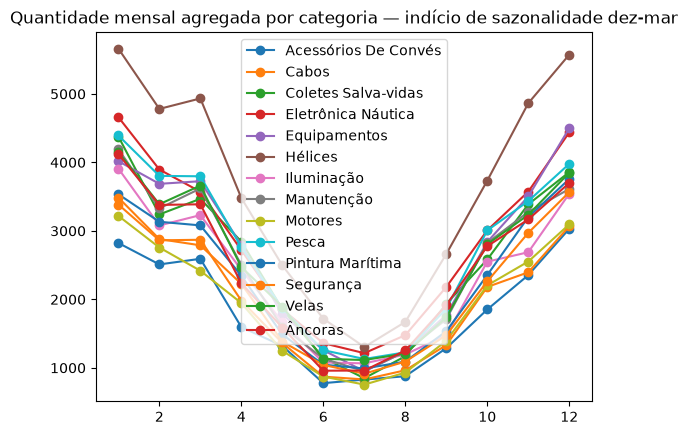

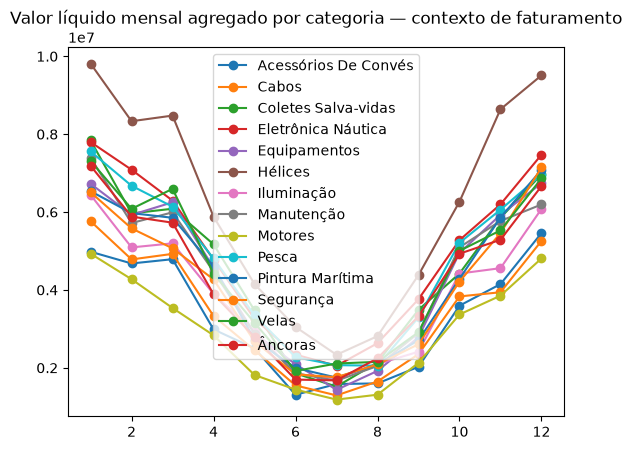

In [16]:
df_cat = run_query("""
    SELECT category_name, mes,
           SUM(quantidade_mes)    AS quantidade_total,
           SUM(valor_liquido_mes) AS valor_total
    FROM eda_base
    GROUP BY category_name, mes
    ORDER BY category_name, mes
""")

# Sazonalidade de demanda: primária por quantidade
for cat in df_cat.category_name.unique():
    sub = df_cat[df_cat.category_name == cat]
    plt.plot(sub.mes, sub.quantidade_total, marker='o', label=cat)
plt.legend(); plt.title("Quantidade mensal agregada por categoria — indício de sazonalidade dez-mar")
plt.show()

# Leitura secundária (contexto de faturamento/ROI, não usada para decidir sazonalidade de demanda)
for cat in df_cat.category_name.unique():
    sub = df_cat[df_cat.category_name == cat]
    plt.plot(sub.mes, sub.valor_total, marker='o', label=cat)
plt.legend(); plt.title("Valor líquido mensal agregado por categoria — contexto de faturamento")
plt.show()

### Célula 5.2

periodo             alta_temporada  resto_do_ano  indice_sazonalidade
product_variant_id                                                   
3                        15.157895      6.777778             2.236411
763                      12.761905      6.107143             2.089669
965                      13.277778      6.500000             2.042735
769                      13.888889      6.920000             2.007065
441                      10.909091      5.714286             1.909091
524                      13.350000      7.000000             1.907143
682                      12.315789      6.531250             1.885671
735                      14.100000      7.500000             1.880000
644                      13.400000      7.137931             1.877295
592                      13.050000      6.954545             1.876471


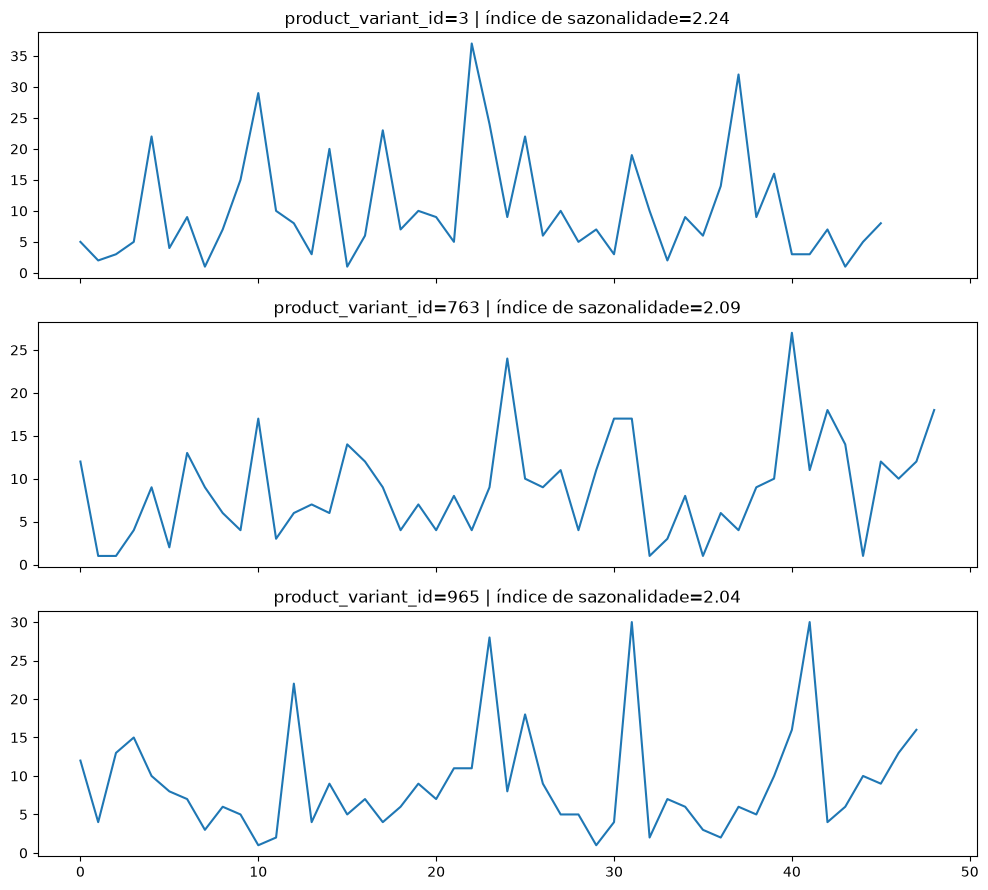

In [ ]:
# 1. Demanda por variante e mês, somando todas as lojas e todos os anos disponíveis
df_variant_month = run_query("""
    SELECT product_variant_id, ano, mes, SUM(quantidade_mes) AS quantidade
    FROM eda_base
    GROUP BY product_variant_id, ano, mes
""")

# 2. Filtrar fora variantes de volume muito baixo (evita indicador de sazonalidade "de ruído")
volume_por_variante = df_vol.groupby('product_variant_id')['quantidade_total'].sum()
limiar_volume_provisorio = volume_por_variante.median()   # provisório, só para esta pré-seleção
variantes_com_volume = volume_por_variante[volume_por_variante >= limiar_volume_provisorio].index
df_variant_month = df_variant_month[df_variant_month.product_variant_id.isin(variantes_com_volume)]

# 3. Indicador de sazonalidade: demanda média em dez/jan/fev/mar vs. demanda média no resto do ano
MESES_ALTA_TEMPORADA = [12, 1, 2, 3]
df_variant_month['periodo'] = df_variant_month['mes'].apply(
    lambda m: 'alta_temporada' if m in MESES_ALTA_TEMPORADA else 'resto_do_ano'
)

medias = (
    df_variant_month
    .groupby(['product_variant_id', 'periodo'])['quantidade']
    .mean()
    .unstack('periodo')
    .dropna()   # descarta variantes sem dado em algum dos dois períodos
)
medias = medias[medias['resto_do_ano'] > 0]   # evita divisão por zero
medias['indice_sazonalidade'] = medias['alta_temporada'] / medias['resto_do_ano']

candidatos_sazonalidade = medias.sort_values('indice_sazonalidade', ascending=False).head(10)
print(candidatos_sazonalidade)

# 4. Inspeção visual das 3 melhores candidatas, para confirmar que o número reflete um padrão real e não um artefato
top3_variantes = candidatos_sazonalidade.head(3).index.tolist()
fig, axes = plt.subplots(len(top3_variantes), 1, figsize=(10, 3*len(top3_variantes)), sharex=True)
for ax, variant_id in zip(axes, top3_variantes):
    sub = df_variant_month[df_variant_month.product_variant_id == variant_id].sort_values(['ano', 'mes'])
    ax.plot(range(len(sub)), sub['quantidade'])
    ax.set_title(f"product_variant_id={variant_id} | índice de sazonalidade={candidatos_sazonalidade.loc[variant_id, 'indice_sazonalidade']:.2f}")
plt.tight_layout()
plt.show()

### Célula 6

In [18]:
q99 = df_serie['quantidade_mes'].quantile(0.99)
outliers = df_serie[df_serie['quantidade_mes'] > q99].sort_values('quantidade_mes', ascending=False)
outliers[['product_variant_id','location_id','mes_ref','quantidade_mes','valor_liquido_mes']]

,product_variant_id,location_id,mes_ref,quantidade_mes,valor_liquido_mes
32671,374,2,2025-12-01,39,33017.46
59886,116,4,2025-11-01,37,94177.31
57081,372,4,2026-03-01,36,103105.09
28907,776,3,2024-12-01,36,79308.52
16852,347,2,2026-11-01,33,85638.28
...,...,...,...,...,...
60636,686,4,2023-07-01,20,57279.72
60538,415,4,2025-10-01,20,56930.80
1455,1003,3,2026-09-01,20,38951.93
1332,496,3,2025-05-01,20,25537.21


### Célula 7

In [19]:
run_query("""
    SELECT
        c.feriado,
        c.fim_de_semana,
        AVG(f.valor_liquido_item) AS ticket_medio_dia
    FROM fct_orders f
    JOIN dim_calendar c ON f.placed_at_key = c.date_key
    GROUP BY c.feriado, c.fim_de_semana
""")

,feriado,fim_de_semana,ticket_medio_dia
0,False,True,9554.273680
1,True,True,9580.455973
2,True,False,9764.007258
3,False,False,9535.203800


In [20]:
connection.close()